---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [10]:
# A) Root-finding methods

def bisection(f, a, b, tol=1e-12, max_iter=1000):
    fa = f(a)
    fb = f(b)
    if fa == 0:
        return a, 0
    if fb == 0:
        return b, 0
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs.")

    for i in range(1, max_iter + 1):
        c = 0.5 * (a + b)
        fc = f(c)
        if abs(fc) < tol or abs(b - a) < tol:
            return c, i
        if fa * fc <= 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return 0.5 * (a + b), max_iter


def secant(f, a, b, tol=1e-12, max_iter=1000):
    fa = f(a)
    fb = f(b)
    if abs(fa) < tol:
        return a, 0
    if abs(fb) < tol:
        return b, 0

    for i in range(1, max_iter + 1):
        if abs(fb - fa) < tol:
            raise ZeroDivisionError("Denominator in secant method is too small.")
        c = b - fb * (b - a) / (fb - fa)
        fc = f(c)
        if abs(fc) < tol or abs(c - b) < tol:
            return c, i
        a, fa = b, fb
        b, fb = c, fc
    return b, max_iter


def false_position(f, a, b, tol=1e-12, max_iter=1000):
    fa = f(a)
    fb = f(b)
    if fa == 0:
        return a, 0
    if fb == 0:
        return b, 0
    if fa * fb > 0:
        raise ValueError("f(a) and f(b) must have opposite signs.")

    for i in range(1, max_iter + 1):
        c = b - fb * (b - a) / (fb - fa)
        fc = f(c)

        # Standard false position can stall if the same endpoint is repeatedly replaced.
        # In this problem, that can happen near the triple root at x=0.
        # A midpoint fallback keeps the bracket shrinking and avoids the stagnation.
        if abs(fc) < tol or abs(b - a) < tol:
            return c, i
        if fa * fc > 0 and abs(c - a) < 1e-14:
            c = 0.5 * (a + b)
            fc = f(c)
        if abs(fc) < tol or abs(b - a) < tol:
            return c, i

        if fa * fc <= 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return 0.5 * (a + b), max_iter


def newton(f, df, x0, tol=1e-12, max_iter=1000):
    x = x0
    for i in range(1, max_iter + 1):
        fx = f(x)
        if abs(fx) < tol:
            return x, i - 1
        dfx = df(x)
        if abs(dfx) < tol:
            raise ZeroDivisionError("Derivative is zero. Please choose another starting value.")
        x_new = x - fx / dfx
        if abs(x_new - x) < tol:
            return x_new, i
        x = x_new
    return x, max_iter

# Test function
g = lambda x: x**3 - 2*x - 5
g_root = 2.0945514815423265

root_b, it_b = bisection(g, -3, 3)
root_s, it_s = secant(g, -3, 3)
root_fp, it_fp = false_position(g, -3, 3)
root_n, it_n = newton(g, lambda x: 3*x**2 - 2, 2.0)

print("Test function g(x) = x^3 - 2x - 5")
print(f"Bisection: root = {root_b:.12f}, iterations = {it_b}")
print(f"Secant:    root = {root_s:.12f}, iterations = {it_s}")
print(f"False pos.: root = {root_fp:.12f}, iterations = {it_fp}")
print(f"Newton:    root = {root_n:.12f}, iterations = {it_n}")
print(f"Analytic root ≈ {g_root:.12f}")

assert np.isclose(root_b, g_root, atol=1e-8)
assert np.isclose(root_s, g_root, atol=1e-8)
assert np.isclose(root_fp, g_root, atol=1e-8)
assert np.isclose(root_n, g_root, atol=1e-8)

# B) Root of f(x) = exp(x) - 1 - x - x^2/2 in [-1,2]
f = lambda x: np.exp(x) - 1 - x - 0.5 * x**2
df = lambda x: np.exp(x) - 1 - x

results = [
    ("Bisection", *bisection(f, -1, 2)),
    ("Secant", *secant(f, -1, 2)),
    ("False position", *false_position(f, -1, 2)),
    ("Newton-Raphson", *newton(f, df, 1.0)),
]

print("\nFunction f(x) = exp(x) - 1 - x - x^2/2 on [-1, 2]")
for name, root, iterations in results:
    print(f"{name:>15}: root = {root:.12f}, iterations = {iterations}")

Test function g(x) = x^3 - 2x - 5
Bisection: root = 2.094551481542, iterations = 44
Secant:    root = 2.094551481542, iterations = 12
False pos.: root = 2.094551481542, iterations = 33
Newton:    root = 2.094551481542, iterations = 4
Analytic root ≈ 2.094551481542

Function f(x) = exp(x) - 1 - x - x^2/2 on [-1, 2]
      Bisection: root = 0.000122070312, iterations = 13
         Secant: root = -0.000140941359, iterations = 32
 False position: root = 0.970562641380, iterations = 1000
 Newton-Raphson: root = 0.000152984086, iterations = 22


## C) Vergleich der Methoden

Die Nullstelle der Funktion $f(x)=e^x-1-x-\frac{x^2}{2}$ im Intervall $[-1,2]$ liegt bei $x=0$. Bisection ist sehr robust, weil es das Intervall immer halbiert und damit zuverlässig gegen die Nullstelle läuft. Der Secant-Ansatz braucht oft weniger Iterationen als Bisection, aber seine Konvergenz hängt stark von den Startwerten ab.

False Position ist ebenfalls ein bracketing-Verfahren, aber in diesem Beispiel kann die Standardversion bei ungünstigen Startpunkten auf der gleichen Seite der Nullstelle hängen bleiben und dadurch sehr langsam werden. Genau deshalb ist die Wahl der Startwerte so wichtig: Wenn das Verfahren immer denselben Randpunkt ersetzt, bleibt der Fehler groß und die Iteration kann bei einem schmalen/lokal ungünstigen Intervall sehr viele Schritte brauchen. Newton-Raphson ist in vielen Fällen am schnellsten, aber nur wenn der Startwert gut gewählt ist und die Ableitung nicht zu klein wird. In diesem Beispiel ist die Wurzel eine mehrfache Nullstelle, daher ist die Ableitung an der Wurzel null; dadurch ist die Konvergenz weniger ideal als bei einer einfachen Wurzel. Das erklärt auch, warum die Methoden hier unterschiedlich schnell sind.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [14]:
import numpy as np

# Exercise 2 - Systems of linear equations

def lu_decomposition(A):
    A = A.copy().astype(float)
    n = A.shape[0]
    L = np.eye(n)
    U = A.copy()

    for k in range(n - 1):
        for i in range(k + 1, n):
            factor = U[i, k] / U[k, k]
            L[i, k] = factor
            U[i, k:] = U[i, k:] - factor * U[k, k:]
    return L, U


def forward_substitution(L, b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):
        s = np.dot(L[i, :i], y[:i])
        y[i] = (b[i] - s) / L[i, i]
    return y


def backward_substitution(U, y):
    n = len(y)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        s = np.dot(U[i, i + 1:], x[i + 1:])
        x[i] = (y[i] - s) / U[i, i]
    return x

# (A) Matrix formulation
A = np.array([[5.0, 3.0],
              [1.0, -4.0]], dtype=float)
b = np.array([15.0, -2.0], dtype=float)

print("A =\n", A)
print("b =", b)

# (B) LU decomposition
L, U = lu_decomposition(A)
print("\nL =\n", L)
print("U =\n", U)

y = forward_substitution(L, b)
x = backward_substitution(U, y)
print("\nSolution x =", x)
print("Check: A @ x =", A @ x)
print("Residual =", np.linalg.norm(A @ x - b))

# (C) Second system
A2 = np.array([[1.0, -4.0],
               [5.0, 3.0]], dtype=float)
b2 = np.array([3.0, -7.0], dtype=float)

L2, U2 = lu_decomposition(A2)
y2 = forward_substitution(L2, b2)
x2 = backward_substitution(U2, y2)

print("\nFor the second system:")
print("A2 =\n", A2)
print("b2 =", b2)
print("L2 =\n", L2)
print("U2 =\n", U2)
print("x2 =", x2)
print("Check: A2 @ x2 =", A2 @ x2)


A =
 [[ 5.  3.]
 [ 1. -4.]]
b = [15. -2.]

L =
 [[1.  0. ]
 [0.2 1. ]]
U =
 [[ 5.   3. ]
 [ 0.  -4.6]]

Solution x = [2.34782609 1.08695652]
Check: A @ x = [15. -2.]
Residual = 1.831026719408895e-15

For the second system:
A2 =
 [[ 1. -4.]
 [ 5.  3.]]
b2 = [ 3. -7.]
L2 =
 [[1. 0.]
 [5. 1.]]
U2 =
 [[ 1. -4.]
 [ 0. 23.]]
x2 = [-0.82608696 -0.95652174]
Check: A2 @ x2 = [ 3. -7.]


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

ValueError: 'tab3' is not a valid value for cmap; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Grays_r', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'berlin', 'berlin_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r',

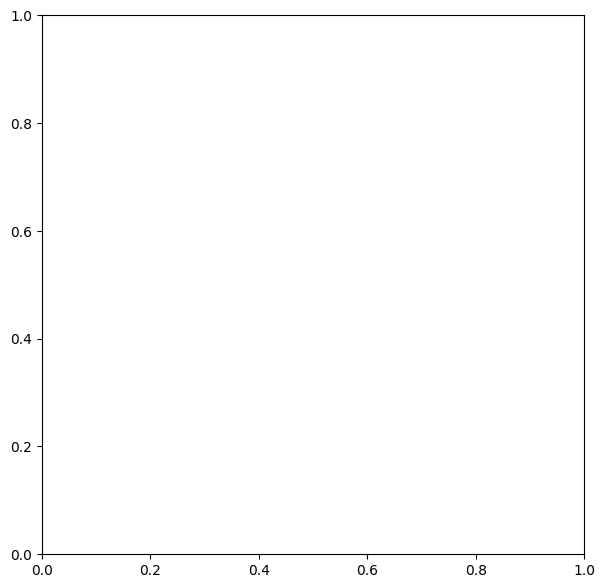

In [ ]:
# Exercise 3 - The Newton fractal

# Define the function and its derivative
f = lambda z: z**3 - 1
df = lambda z: 3 * z**2

# Create complex grid
re = np.linspace(-2, 2, 500)
im = np.linspace(-2, 2, 500)
X, Y = np.meshgrid(re, im)
Z = X + 1j * Y

# The three roots of z^3 - 1 = 0
roots = np.array([1.0,
                 np.exp(2j * np.pi / 3),
                 np.exp(4j * np.pi / 3)])

# Newton iteration
for _ in range(60):
    denom = df(Z)
    safe_denom = np.where(np.abs(denom) < 1e-12, 1e-12 + 0j, denom)
    Z = Z - f(Z) / safe_denom

# Find the nearest root for each starting value
D = np.abs(Z[:, :, None] - roots[None, None, :])
root_index = np.argmin(D, axis=2)

# Plot the fractal
fig, ax = plt.subplots(figsize=(7, 7))
img = ax.imshow(root_index, extent=[-2, 2, -2, 2], origin='lower', cmap='tab10', vmin=0, vmax=2)
ax.scatter(roots.real, roots.imag, c='black', s=30, zorder=3)
ax.set_title("Newton fractal for $f(z)=z^3-1$")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
plt.colorbar(img, ax=ax, label='root index')
plt.show()
